# Paper Analysis

Each Likert response is encoded as: strongly disagree = -2, disagree = -1, neutral = 0, agree = 1, strongly agree = 2. For each experiment e, model m, statement q, scenario c, and round r, a trajectory is the ordered response vector y(e,m,q,c) across five rounds.

Metrics used here:

- Within-question standard deviation: sample SD of the trajectory across rounds.
- First-to-final displacement: absolute distance between the final and initial response.
- Cumulative shift: sum of absolute distances from the initial response over later rounds.


In [24]:
from pathlib import Path
import io
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

try:
    from IPython.display import display, Image
except ImportError:
    Image = None
    def display(obj):
        return None

warnings.filterwarnings('ignore')

ROOT = Path.cwd()
FIG_DIR_PNG = ROOT / 'figures' / 'png'
FIG_DIR_PDF = ROOT / 'figures' / 'pdf'
FIG_DIR_PNG.mkdir(parents=True, exist_ok=True)
FIG_DIR_PDF.mkdir(parents=True, exist_ok=True)

SAVE_FIGURES = True
SHOW_FIGURES_INLINE = True
CLOSE_FIGURES_AFTER_RENDER = True

sns.set_theme(style='whitegrid', context='paper', font_scale=1.35)
plt.rcParams.update({
    'figure.dpi': 140,
    'savefig.dpi': 300,
    'axes.titleweight': 'bold',
    'axes.labelsize': 15,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 12,
    'legend.title_fontsize': 13,
    'axes.labelweight': 'bold',
    'font.family': 'DejaVu Sans',
})

EXPERIMENTS = [
    {'id': 'E1', 'name': 'Free summary', 'path': 'dados/experimento_1/respostas_iterativas.csv', 'intervention': 'summary'},
    {'id': 'E2', 'name': 'Summary protocol v2', 'path': 'dados/experimento_2/respostas_iterativas_v2.csv', 'intervention': 'summary v2'},
    {'id': 'E3', 'name': 'Trade-offs and uncertainty', 'path': 'dados/experimento_3/respostas_iterativas_v3.csv', 'intervention': 'structured summary'},
]
EXPERIMENT_ORDER = [meta['id'] for meta in EXPERIMENTS]
TENDENCY_LABELS = {'esquerda': 'Left', 'neutro': 'Neutral', 'direita': 'Right'}
FIGURE_EXPERIMENT_LABELS = {
    'E1': 'E1 — Free summary',
    'E2': 'E2 — Negative points and positive\npoints',
    'E3': 'E3 — Trade-offs and uncertainty',
}

SHORT_MODEL_NAMES = {
    'Qwen/Qwen3-14B': 'Qwen3 14B',
    'Qwen/Qwen3-30B-A3B': 'Qwen3 30B',
    'Qwen/Qwen3.6-35B-A3B': 'Qwen3.6 35B',
    'deepseek-ai/DeepSeek-V4-Flash': 'DeepSeek V4',
    'deepseek-ai/DeepSeek-V3.2': 'DeepSeek V3.2',
    'google/gemma-3-4b-it': 'Gemma 3 4B',
    'google/gemma-4-31B-it': 'Gemma 4 31B',
    'meta-llama/Llama-4-Scout-17B-16E-Instruct': 'Llama 4 Scout',
    'meta-llama/Meta-Llama-3.1-8B-Instruct': 'Llama 3.1 8B',
    'mistralai/Mistral-Nemo-Instruct-2407': 'Mistral Nemo',
    'mistralai/Mistral-Small-3.2-24B-Instruct-2506': 'Mistral Small',
}

MODEL_METADATA = {
    'Qwen/Qwen3-14B': {'family': 'Qwen', 'params_b': 14.0},
    'Qwen/Qwen3-30B-A3B': {'family': 'Qwen', 'params_b': 30.0},
    'Qwen/Qwen3.6-35B-A3B': {'family': 'Qwen', 'params_b': 35.0},
    'google/gemma-3-4b-it': {'family': 'Gemma', 'params_b': 4.0},
    'google/gemma-4-31B-it': {'family': 'Gemma', 'params_b': 31.0},
    'meta-llama/Llama-4-Scout-17B-16E-Instruct': {'family': 'Llama', 'params_b': 17.0},
    'meta-llama/Meta-Llama-3.1-8B-Instruct': {'family': 'Llama', 'params_b': 8.0},
    'mistralai/Mistral-Nemo-Instruct-2407': {'family': 'Mistral', 'params_b': 12.0},
    'mistralai/Mistral-Small-3.2-24B-Instruct-2506': {'family': 'Mistral', 'params_b': 24.0},
    'deepseek-ai/DeepSeek-V4-Flash': {'family': 'DeepSeek', 'params_b': 13.0},
    'deepseek-ai/DeepSeek-V3.2': {'family': 'DeepSeek', 'params_b': 37.0},
}

AXIS_SHORT_NAMES = {
    'Corrupção e Justiça': 'Corruption/justice',
    'Economia': 'Economy',
    'Educação e Cultura': 'Education/culture',
    'Instituições Democráticas': 'Democratic inst.',
    'Meio Ambiente': 'Environment',
    'Políticas Sociais': 'Social policy',
    'Segurança Pública': 'Public security',
}


In [25]:
def short_model_name(model):
    return SHORT_MODEL_NAMES.get(model, str(model).split('/')[-1].replace('-Instruct', '')[:22])


def finish_figure(fig, name):
    png = FIG_DIR_PNG / f'{name}.png'
    pdf = FIG_DIR_PDF / f'{name}.pdf'
    if SAVE_FIGURES:
        fig.savefig(png, bbox_inches='tight')
        fig.savefig(pdf, bbox_inches='tight')
        print(f'Saved {png.relative_to(ROOT)} and {pdf.relative_to(ROOT)}')
    if SHOW_FIGURES_INLINE and Image is not None:
        if SAVE_FIGURES:
            display(Image(filename=str(png)))
        else:
            buffer = io.BytesIO()
            fig.savefig(buffer, format='png', bbox_inches='tight')
            display(Image(data=buffer.getvalue()))
    if CLOSE_FIGURES_AFTER_RENDER:
        plt.close(fig)


def load_experiment(meta):
    df = pd.read_csv(ROOT / meta['path'])
    df['experiment'] = meta['id']
    df['experiment_name'] = meta['name']
    df['intervention'] = meta['intervention']
    df['rodada'] = pd.to_numeric(df.get('rodada', 1), errors='coerce').fillna(1).astype(int)
    df['likert_valor'] = pd.to_numeric(df.get('likert_valor'), errors='coerce')
    for col in ['modelo', 'provider', 'eixo', 'tipo_pergunta', 'pergunta', 'tendencia', 'pair_id', 'temperatura', 'repeticao']:
        if col not in df.columns:
            df[col] = np.nan
    df['condition'] = df['tendencia'].map(TENDENCY_LABELS).fillna(df['tendencia'])
    df['question_id'] = df['pair_id'].astype(str) + '|' + df['tipo_pergunta'].astype(str) + '|' + df['pergunta'].astype(str)
    return df


def build_round_level(valid):
    return (
        valid.groupby(
            ['experiment', 'experiment_name', 'intervention', 'modelo', 'condition', 'tendencia', 'eixo', 'question_id', 'rodada'],
            dropna=False,
        )['likert_valor']
        .mean()
        .reset_index()
        .sort_values(['experiment', 'modelo', 'condition', 'eixo', 'question_id', 'rodada'])
    )


def build_trajectories(round_level):
    rows = []
    group_cols = ['experiment', 'experiment_name', 'intervention', 'modelo', 'condition', 'tendencia', 'eixo', 'question_id']
    for keys, group in round_level.groupby(group_cols, dropna=False):
        ordered = group.sort_values('rodada')
        values = ordered['likert_valor'].to_numpy(dtype=float)
        rounds = ordered['rodada'].to_numpy(dtype=int)
        if len(values) == 0:
            continue
        diffs = np.diff(values)
        first = values[0]
        final = values[-1]
        rows.append({
            'experiment': keys[0],
            'experiment_name': keys[1],
            'intervention': keys[2],
            'modelo': keys[3],
            'condition': keys[4],
            'tendencia': keys[5],
            'eixo': keys[6],
            'question_id': keys[7],
            'n_rounds': len(np.unique(rounds)),
            'first_score': first,
            'final_score': final,
            'std': np.std(values, ddof=0),
            'variance': np.var(values, ddof=0),
            'any_change': float(len(np.unique(values)) > 1),
            'first_to_final_delta': final - first,
            'first_to_final_abs_delta': abs(final - first),
            'max_abs_shift_from_first': float(np.max(np.abs(values - first))),
            'cumulative_abs_shift_from_first': float(np.sum(np.abs(values[1:] - first))) if len(values) > 1 else 0.0,
            'mean_abs_step_change': float(np.mean(np.abs(diffs))) if len(diffs) else 0.0,
        })
    traj = pd.DataFrame(rows)
    return traj[traj['n_rounds'] > 1].copy()

def kruskal_epsilon_squared(h_stat, n, k):
    if pd.isna(h_stat) or n <= k:
        return np.nan
    return max(0.0, (h_stat - k + 1) / (n - k))


def kruskal_by_group(data, value_col, group_col):
    groups = [g[value_col].dropna().to_numpy() for _, g in data.groupby(group_col)]
    groups = [g for g in groups if len(g) > 0]
    if len(groups) < 2:
        return np.nan, np.nan, np.nan, sum(len(g) for g in groups), len(groups)
    h_stat, p_value = stats.kruskal(*groups)
    n = sum(len(g) for g in groups)
    k = len(groups)
    return h_stat, p_value, kruskal_epsilon_squared(h_stat, n, k), n, k


In [26]:
responses = pd.concat([load_experiment(meta) for meta in EXPERIMENTS], ignore_index=True)
valid = responses.dropna(subset=['likert_valor']).copy()
round_level = build_round_level(valid)
trajectories = build_trajectories(round_level)

print(f'Loaded rows: {len(responses):,}')
print(f'Valid Likert rows: {len(valid):,}')
print(f'Multi-round trajectories: {len(trajectories):,}')


Loaded rows: 50,370
Valid Likert rows: 50,234
Multi-round trajectories: 10,078


In [27]:
def plot_figure_2(traj):
    model_order = traj.groupby('modelo')['std'].mean().sort_values(ascending=True).index.tolist()
    label_order = [short_model_name(m) for m in model_order]
    plot_data = traj.copy()
    plot_data['model_short'] = plot_data['modelo'].map(dict(zip(model_order, label_order)))

    fig, axes = plt.subplots(len(EXPERIMENT_ORDER), 1, figsize=(12, 5.4 * len(EXPERIMENT_ORDER)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, exp in zip(axes, EXPERIMENT_ORDER):
        sub = plot_data[plot_data['experiment'] == exp]
        sns.boxplot(
            data=sub,
            y='model_short',
            x='std',
            order=label_order,
            color='#d9e8f5',
            fliersize=2.5,
            linewidth=1.2,
            medianprops={'color': '#b91c1c', 'linewidth': 3.0},
            ax=ax,
        )
        ax.set_title(FIGURE_EXPERIMENT_LABELS[exp], fontsize=15, fontweight='bold')
        ax.set_xlabel('Within-question SD across rounds (0 = unchanged)')
        ax.set_ylabel('Model')
        ax.grid(axis='x', alpha=.25)
    plt.tight_layout()
    finish_figure(fig, 'figure_2')


def plot_figure_3(traj):
    model_protocol = (
        traj.groupby(['experiment', 'experiment_name', 'modelo'], as_index=False)
        .agg(mean_abs_final_move=('first_to_final_abs_delta', 'mean'))
    )
    metadata = pd.DataFrame([{'modelo': model, **meta} for model, meta in MODEL_METADATA.items()])
    size_metric = model_protocol.merge(metadata, on='modelo', how='left')
    size_metric['model_short'] = size_metric['modelo'].map(SHORT_MODEL_NAMES).fillna(size_metric['modelo'].str.split('/').str[-1].str[:22])
    size_metric['experiment_label'] = size_metric['experiment_name']

    aggregated = (
        size_metric.groupby(['modelo', 'family', 'params_b', 'model_short'], dropna=False, as_index=False)
        .agg(mean_abs_final_move=('mean_abs_final_move', 'mean'))
    )
    aggregated['experiment'] = 'Aggregated'
    aggregated['experiment_label'] = 'Aggregated E1/E2/E3'
    size_plot = pd.concat([
        size_metric[['experiment', 'experiment_label', 'modelo', 'family', 'params_b', 'model_short', 'mean_abs_final_move']],
        aggregated[['experiment', 'experiment_label', 'modelo', 'family', 'params_b', 'model_short', 'mean_abs_final_move']],
    ], ignore_index=True)

    panels = EXPERIMENT_ORDER + ['Aggregated']
    panel_titles = {
        'E1': 'Free summary',
        'E2': 'E2 — Negative points and positive\npoints',
        'E3': 'Trade-offs and uncertainty',
        'Aggregated': 'Aggregated E1/E2/E3',
    }
    fig, axes = plt.subplots(2, 2, figsize=(12.4, 9.6))
    axes = axes.ravel()
    legend_handles = legend_labels = None
    for ax, exp in zip(axes, panels):
        sub = size_plot[(size_plot['experiment'] == exp) & size_plot['params_b'].notna()].copy()
        sns.scatterplot(data=sub, x='params_b', y='mean_abs_final_move', hue='family', s=90, ax=ax)
        if legend_handles is None:
            legend_handles, legend_labels = ax.get_legend_handles_labels()
        if len(sub) >= 3 and sub['params_b'].nunique() >= 3:
            sns.regplot(data=sub, x='params_b', y='mean_abs_final_move', scatter=False, color='#334155', ax=ax, truncate=False)
        for _, row in sub.iterrows():
            ax.text(row['params_b'] * 1.015, row['mean_abs_final_move'] + .006, row['model_short'], fontsize=9, alpha=.75)
        ax.set_title(panel_titles[exp])
        ax.set_xlabel('Model size (billions of parameters)')
        ax.set_ylabel('Mean absolute first-to-final movement')
        ax.grid(alpha=.25)
        if ax.get_legend():
            ax.get_legend().remove()
    if legend_handles:
        fig.legend(legend_handles, legend_labels, title='Family', bbox_to_anchor=(1.01, .5), loc='center left', frameon=False)
    plt.tight_layout()
    finish_figure(fig, 'figure_3')


def plot_figure_4(traj):
    tests = []
    for (exp, condition), sub in traj.groupby(['experiment', 'condition']):
        h_stat, p_value, eps2, n, k = kruskal_by_group(sub, 'variance', 'modelo')
        tests.append({'experiment': exp, 'condition': condition, 'p_value': p_value, 'significant': bool(p_value < .05) if not pd.isna(p_value) else False})
    sig_lookup = pd.DataFrame(tests).set_index(['experiment', 'condition'])['significant'].to_dict()

    variance_landscape = (
        traj.groupby(['experiment', 'condition', 'modelo'], as_index=False)
        .agg(mean_variance=('variance', 'mean'))
    )
    variance_landscape['model_short'] = variance_landscape['modelo'].map(SHORT_MODEL_NAMES).fillna(variance_landscape['modelo'].str.split('/').str[-1].str[:18])
    condition_order = [c for c in ['Left', 'Neutral', 'Right'] if c in set(variance_landscape['condition'])]
    column_order = [(exp, cond) for exp in EXPERIMENT_ORDER for cond in condition_order]
    column_labels = []
    for exp, cond in column_order:
        star = '*' if sig_lookup.get((exp, cond), False) else ''
        cond_label = 'no-context' if cond == 'Neutral' else cond
        column_labels.append(f'{exp}\n{cond_label}{star}')
    variance_landscape['column_key'] = variance_landscape.apply(lambda r: f"{r['experiment']}|{r['condition']}", axis=1)
    ordered_keys = [f'{exp}|{cond}' for exp, cond in column_order]
    heat = variance_landscape.pivot_table(index='model_short', columns='column_key', values='mean_variance', aggfunc='mean').reindex(columns=ordered_keys)
    row_order = heat.mean(axis=1).sort_values(ascending=False).index
    heat = heat.loc[row_order]
    heat.columns = column_labels
    bar_values = heat.mean(axis=1)

    fig = plt.figure(figsize=(17.0, max(6.2, .42 * len(heat))))
    gs = fig.add_gridspec(1, 2, width_ratios=[5.5, 1.25], wspace=.08)
    ax_heat = fig.add_subplot(gs[0, 0])
    ax_bar = fig.add_subplot(gs[0, 1], sharey=ax_heat)
    sns.heatmap(heat, cmap='rocket_r', annot=True, annot_kws={'fontsize': 13}, fmt='.2f', linewidths=.5, cbar_kws={'label': 'Mean within-question variance'}, ax=ax_heat)
    ax_heat.set_xlabel('')
    ax_heat.set_ylabel('Model')
    ax_heat.tick_params(axis='x', rotation=0)
    ax_bar.barh(np.arange(len(row_order)) + .5, bar_values, height=.72, color='#475569')
    ax_bar.set_xlabel('Row\nmean')
    ax_bar.set_ylabel('')
    ax_bar.grid(axis='x', alpha=.25)
    ax_bar.tick_params(axis='y', left=False, labelleft=False)
    ax_bar.invert_yaxis()
    for y, value in enumerate(bar_values):
        ax_bar.text(value + .01, y + .5, f'{value:.2f}', va='center', fontsize=11)
    fig.subplots_adjust(bottom=.08, top=.96)
    finish_figure(fig, 'figure_4')


def plot_figure_5(traj):
    axis_summary = (
        traj.groupby(['experiment', 'eixo'], as_index=False)
        .agg(mean_abs_displacement=('first_to_final_abs_delta', 'mean'))
    )
    axis_agg = traj.groupby('eixo', as_index=False).agg(mean_abs_displacement=('first_to_final_abs_delta', 'mean'))
    axis_agg['experiment'] = 'Aggregated'
    axis_plot = pd.concat([axis_summary, axis_agg], ignore_index=True)
    axis_plot['axis_short'] = axis_plot['eixo'].map(AXIS_SHORT_NAMES).fillna(axis_plot['eixo'])
    heat = axis_plot.pivot_table(index='axis_short', columns='experiment', values='mean_abs_displacement').reindex(columns=EXPERIMENT_ORDER + ['Aggregated'])
    heat = heat.loc[heat['Aggregated'].sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(8.8, max(4.8, .5 * len(heat))))
    sns.heatmap(heat, cmap='mako_r', annot=True, annot_kws={'fontsize': 13}, fmt='.2f', linewidths=.5, cbar_kws={'label': 'Mean absolute displacement'}, ax=ax)
    ax.set_xlabel('Experiment')
    ax.set_ylabel('Issue axis')
    ax.tick_params(axis='x', rotation=0)
    plt.tight_layout()
    finish_figure(fig, 'figure_5')


def plot_figure_6(traj):
    cumulative = traj.copy()
    cumulative['model_short'] = cumulative['modelo'].map(SHORT_MODEL_NAMES).fillna(cumulative['modelo'].str.split('/').str[-1].str[:18])
    model_experiment = (
        cumulative.groupby(['experiment', 'modelo', 'model_short'], as_index=False)
        .agg(mean_cumulative_shift=('cumulative_abs_shift_from_first', 'mean'))
    )
    model_agg = cumulative.groupby(['modelo', 'model_short'], as_index=False).agg(mean_cumulative_shift=('cumulative_abs_shift_from_first', 'mean'))
    model_agg['experiment'] = 'Aggregated'
    cum_plot = pd.concat([model_experiment, model_agg], ignore_index=True)
    heat = cum_plot.pivot_table(index='model_short', columns='experiment', values='mean_cumulative_shift').reindex(columns=EXPERIMENT_ORDER + ['Aggregated'])
    heat = heat.loc[heat['Aggregated'].sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(8.6, max(5.4, .5 * len(heat))))
    sns.heatmap(heat, cmap='flare', annot=True, annot_kws={'fontsize': 13}, fmt='.2f', linewidths=.5, cbar_kws={'label': 'Mean cumulative shift score'}, ax=ax)
    ax.set_xlabel('Experiment')
    ax.set_ylabel('Model')
    ax.tick_params(axis='x', rotation=0)
    plt.tight_layout()
    finish_figure(fig, 'figure_6')


Saved figures/png/figure_2.png and figures/pdf/figure_2.pdf


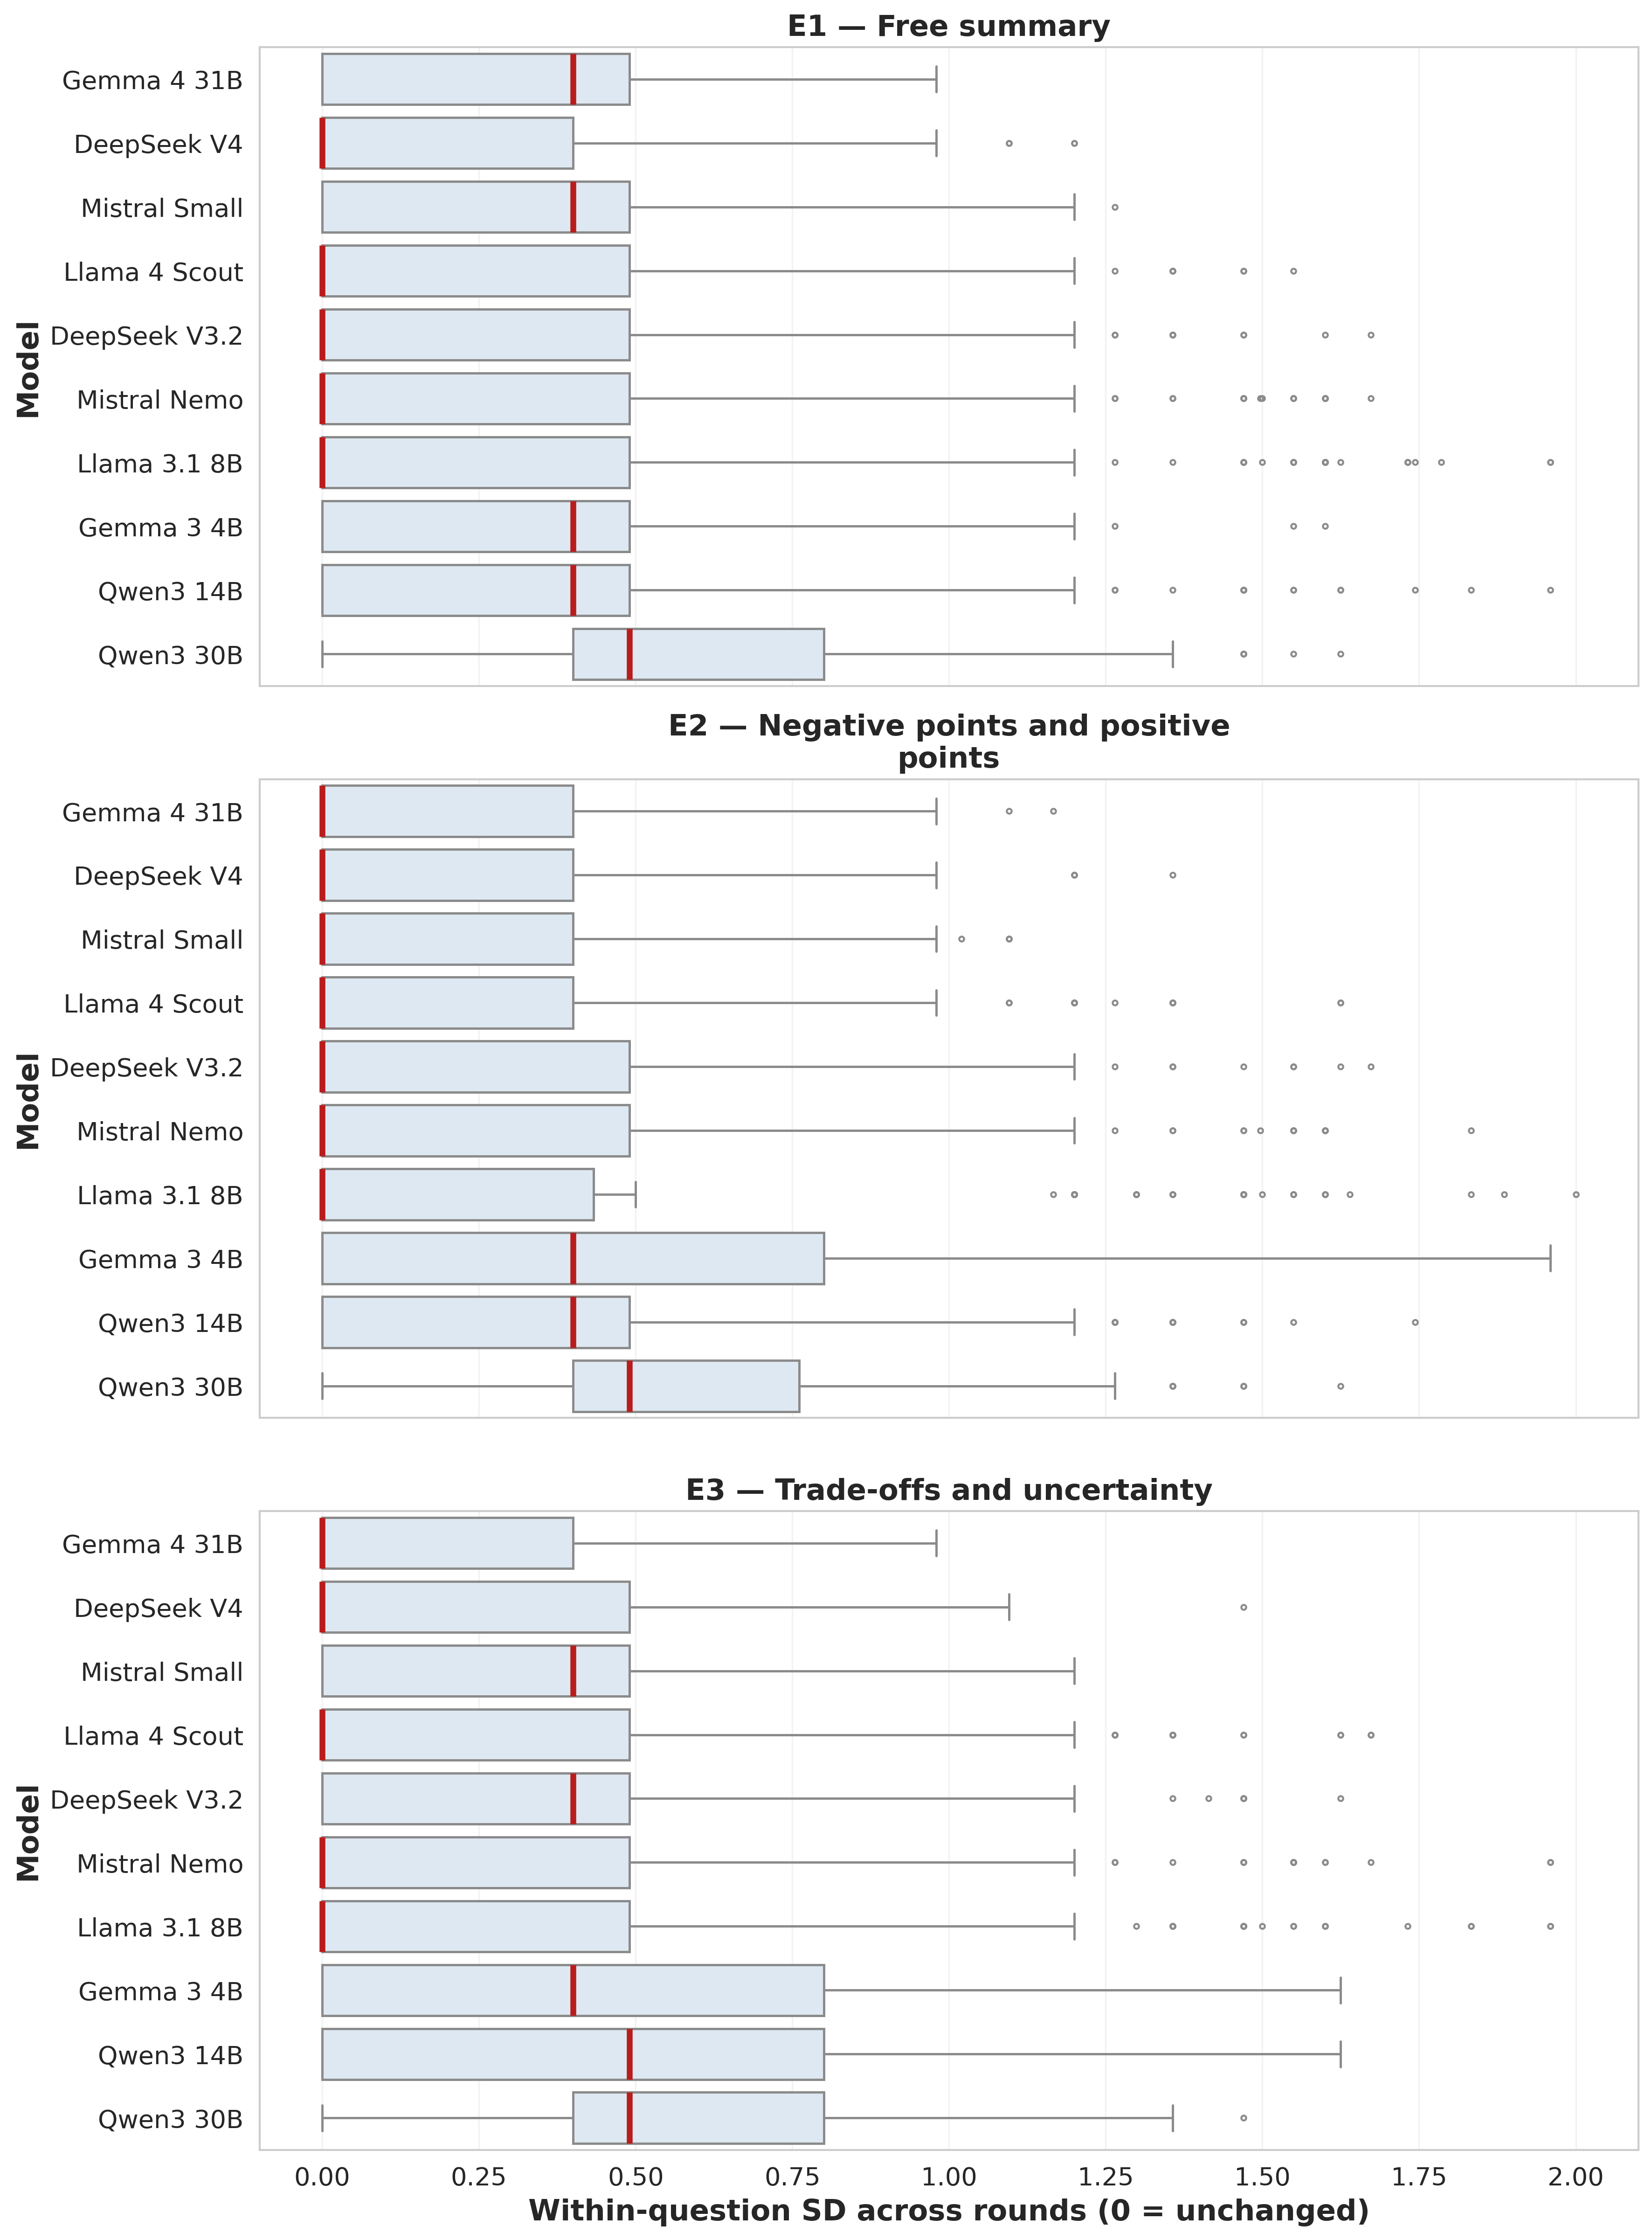

Saved figures/png/figure_3.png and figures/pdf/figure_3.pdf


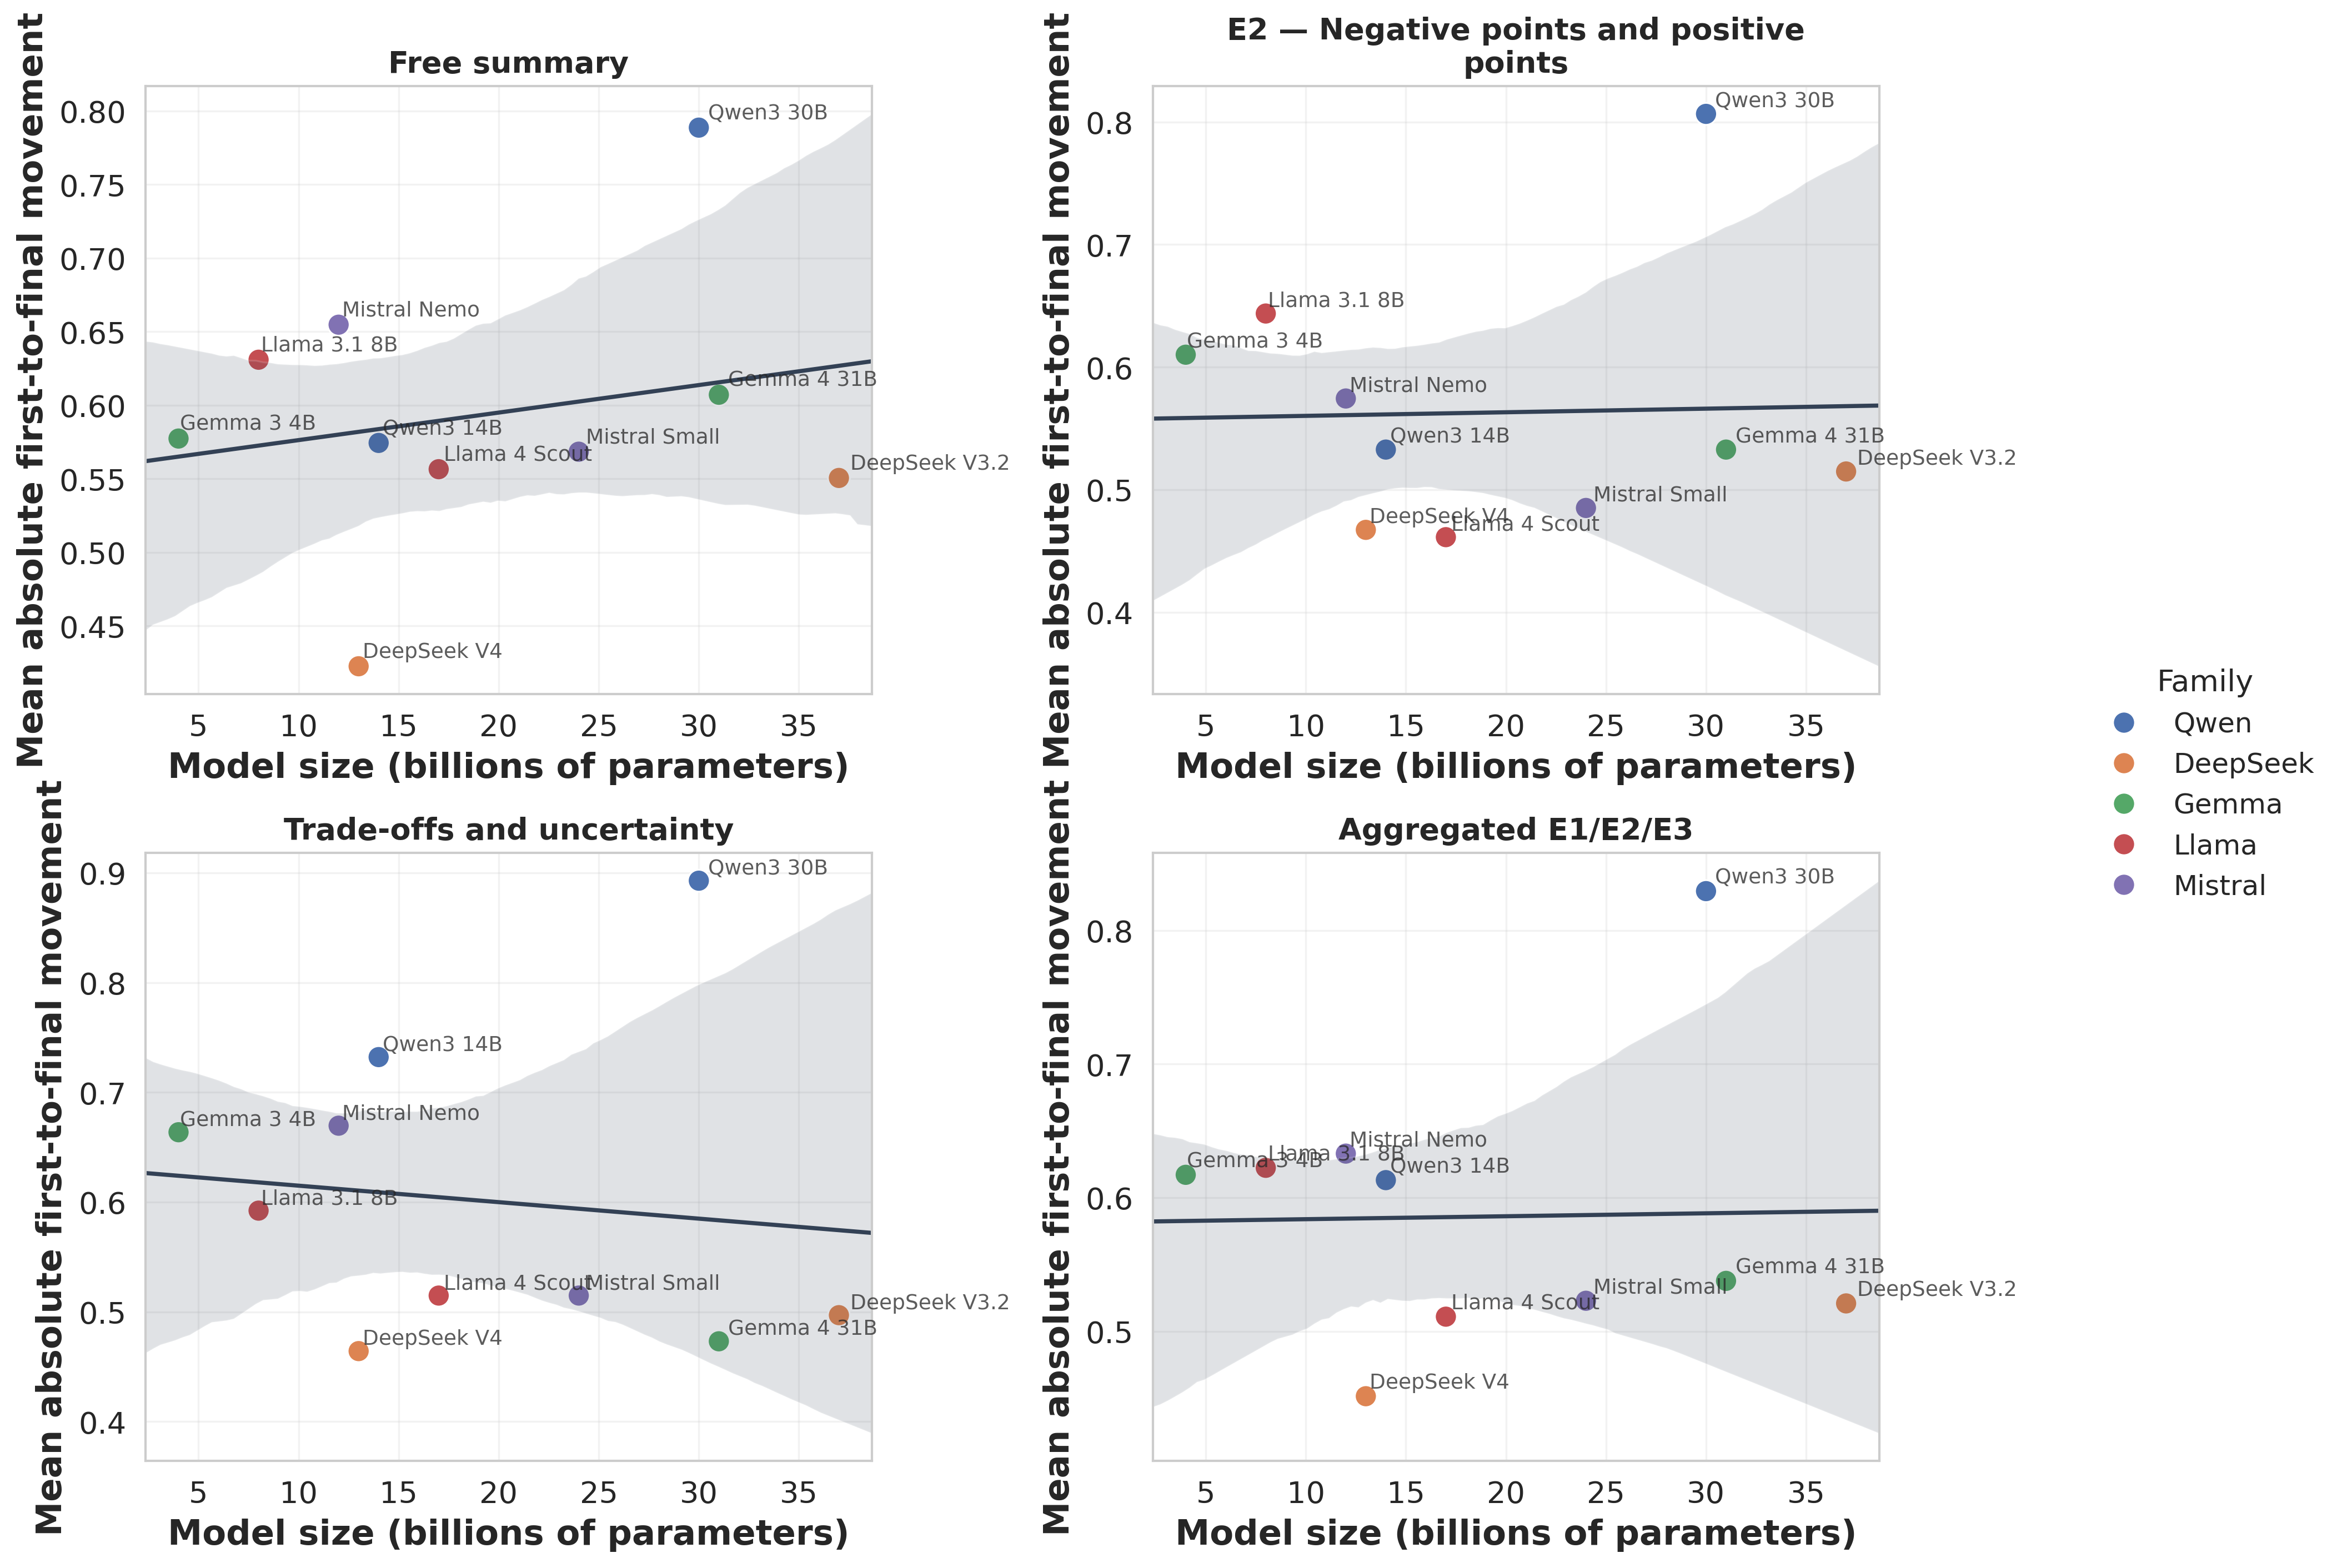

Saved figures/png/figure_4.png and figures/pdf/figure_4.pdf


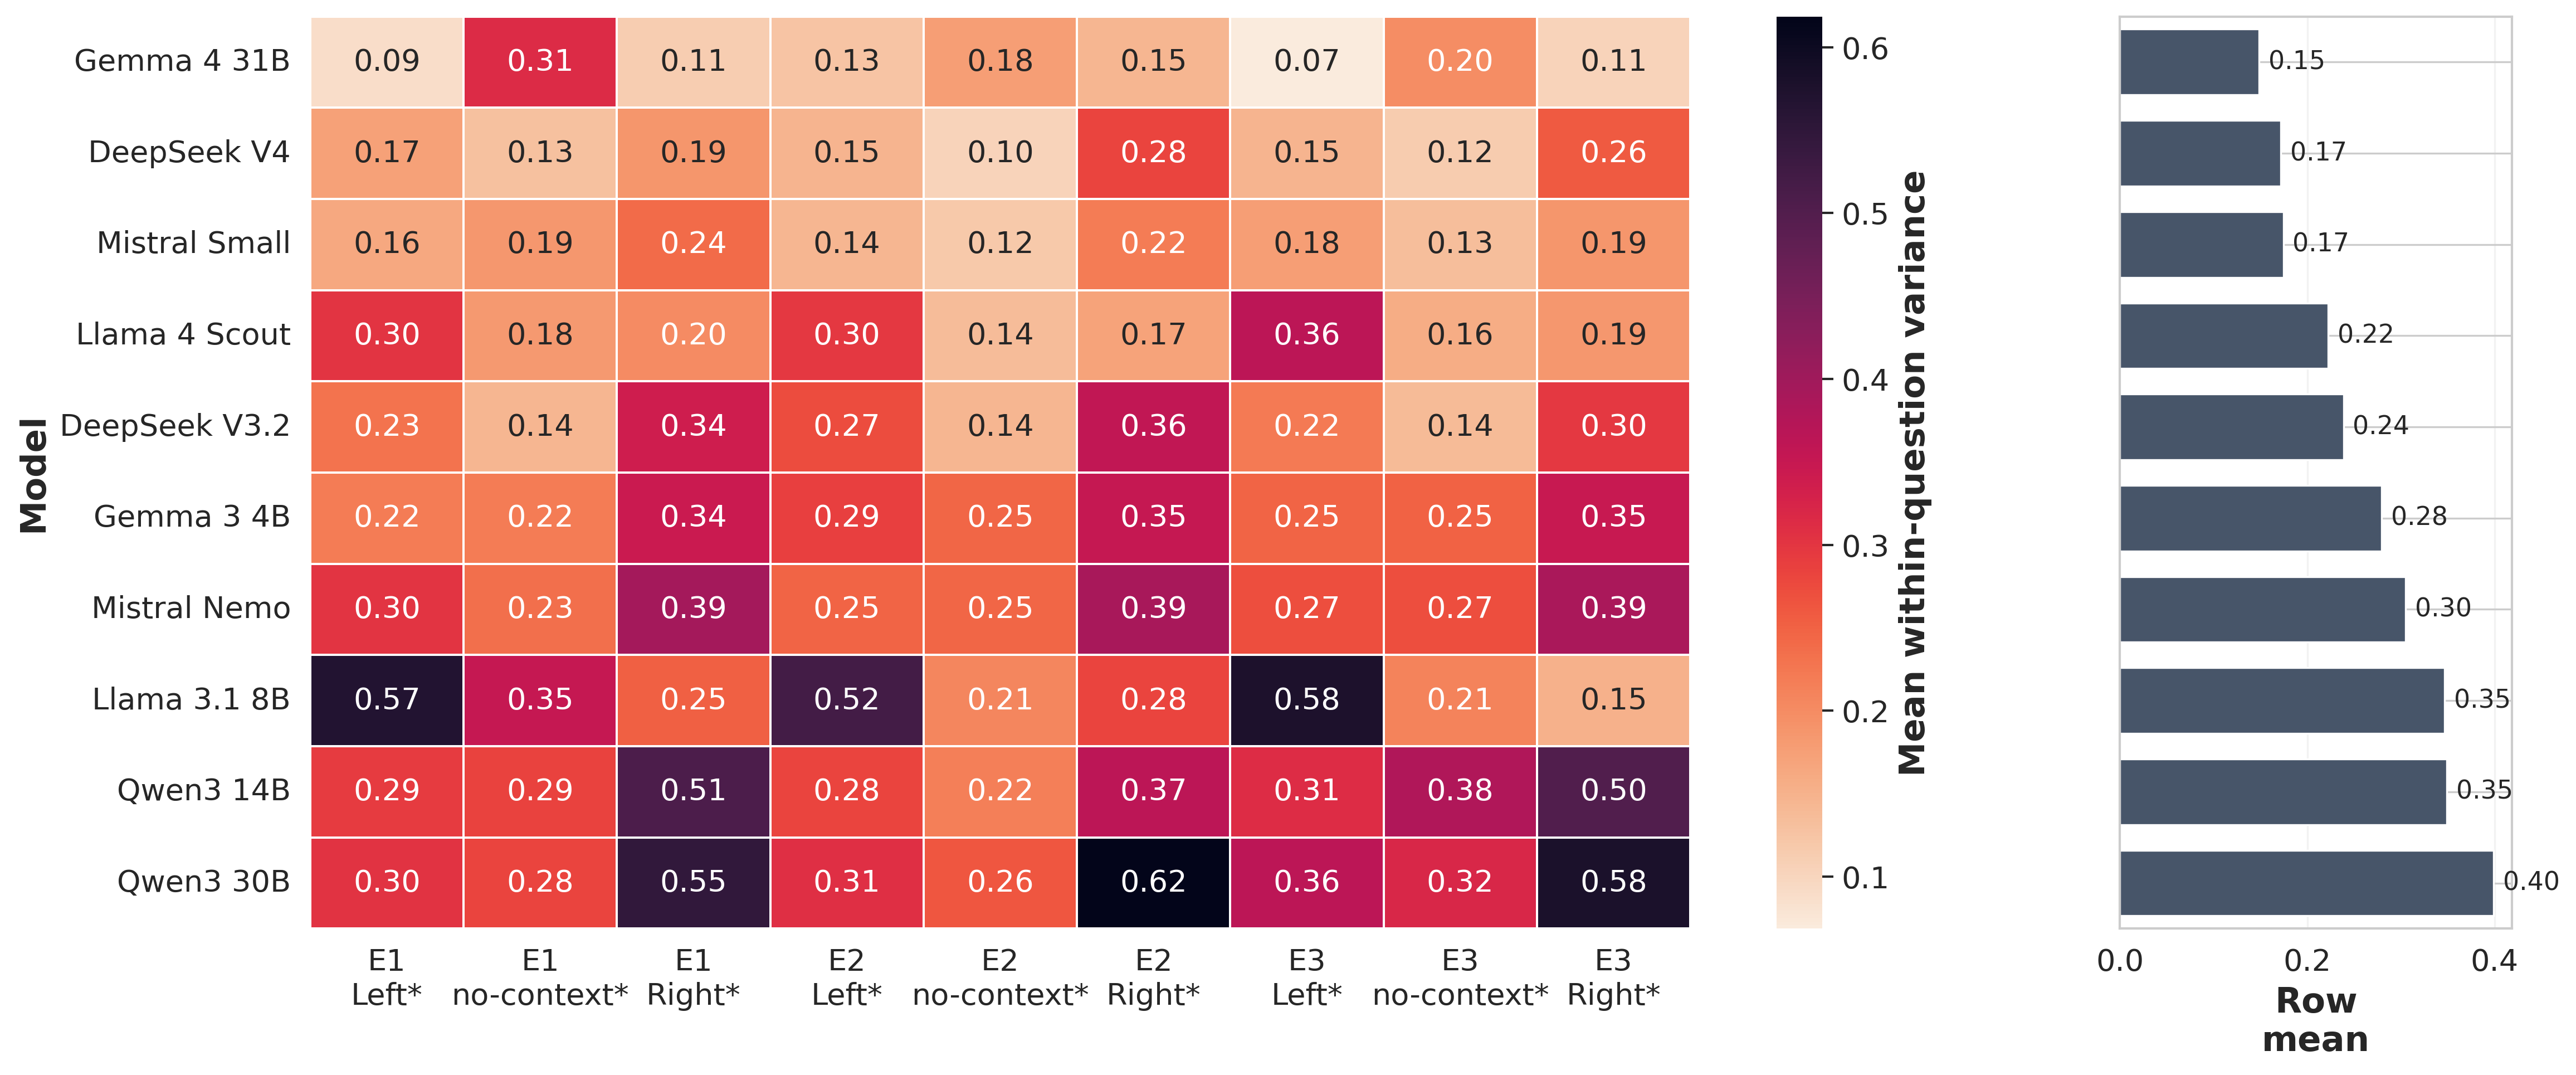

Saved figures/png/figure_5.png and figures/pdf/figure_5.pdf


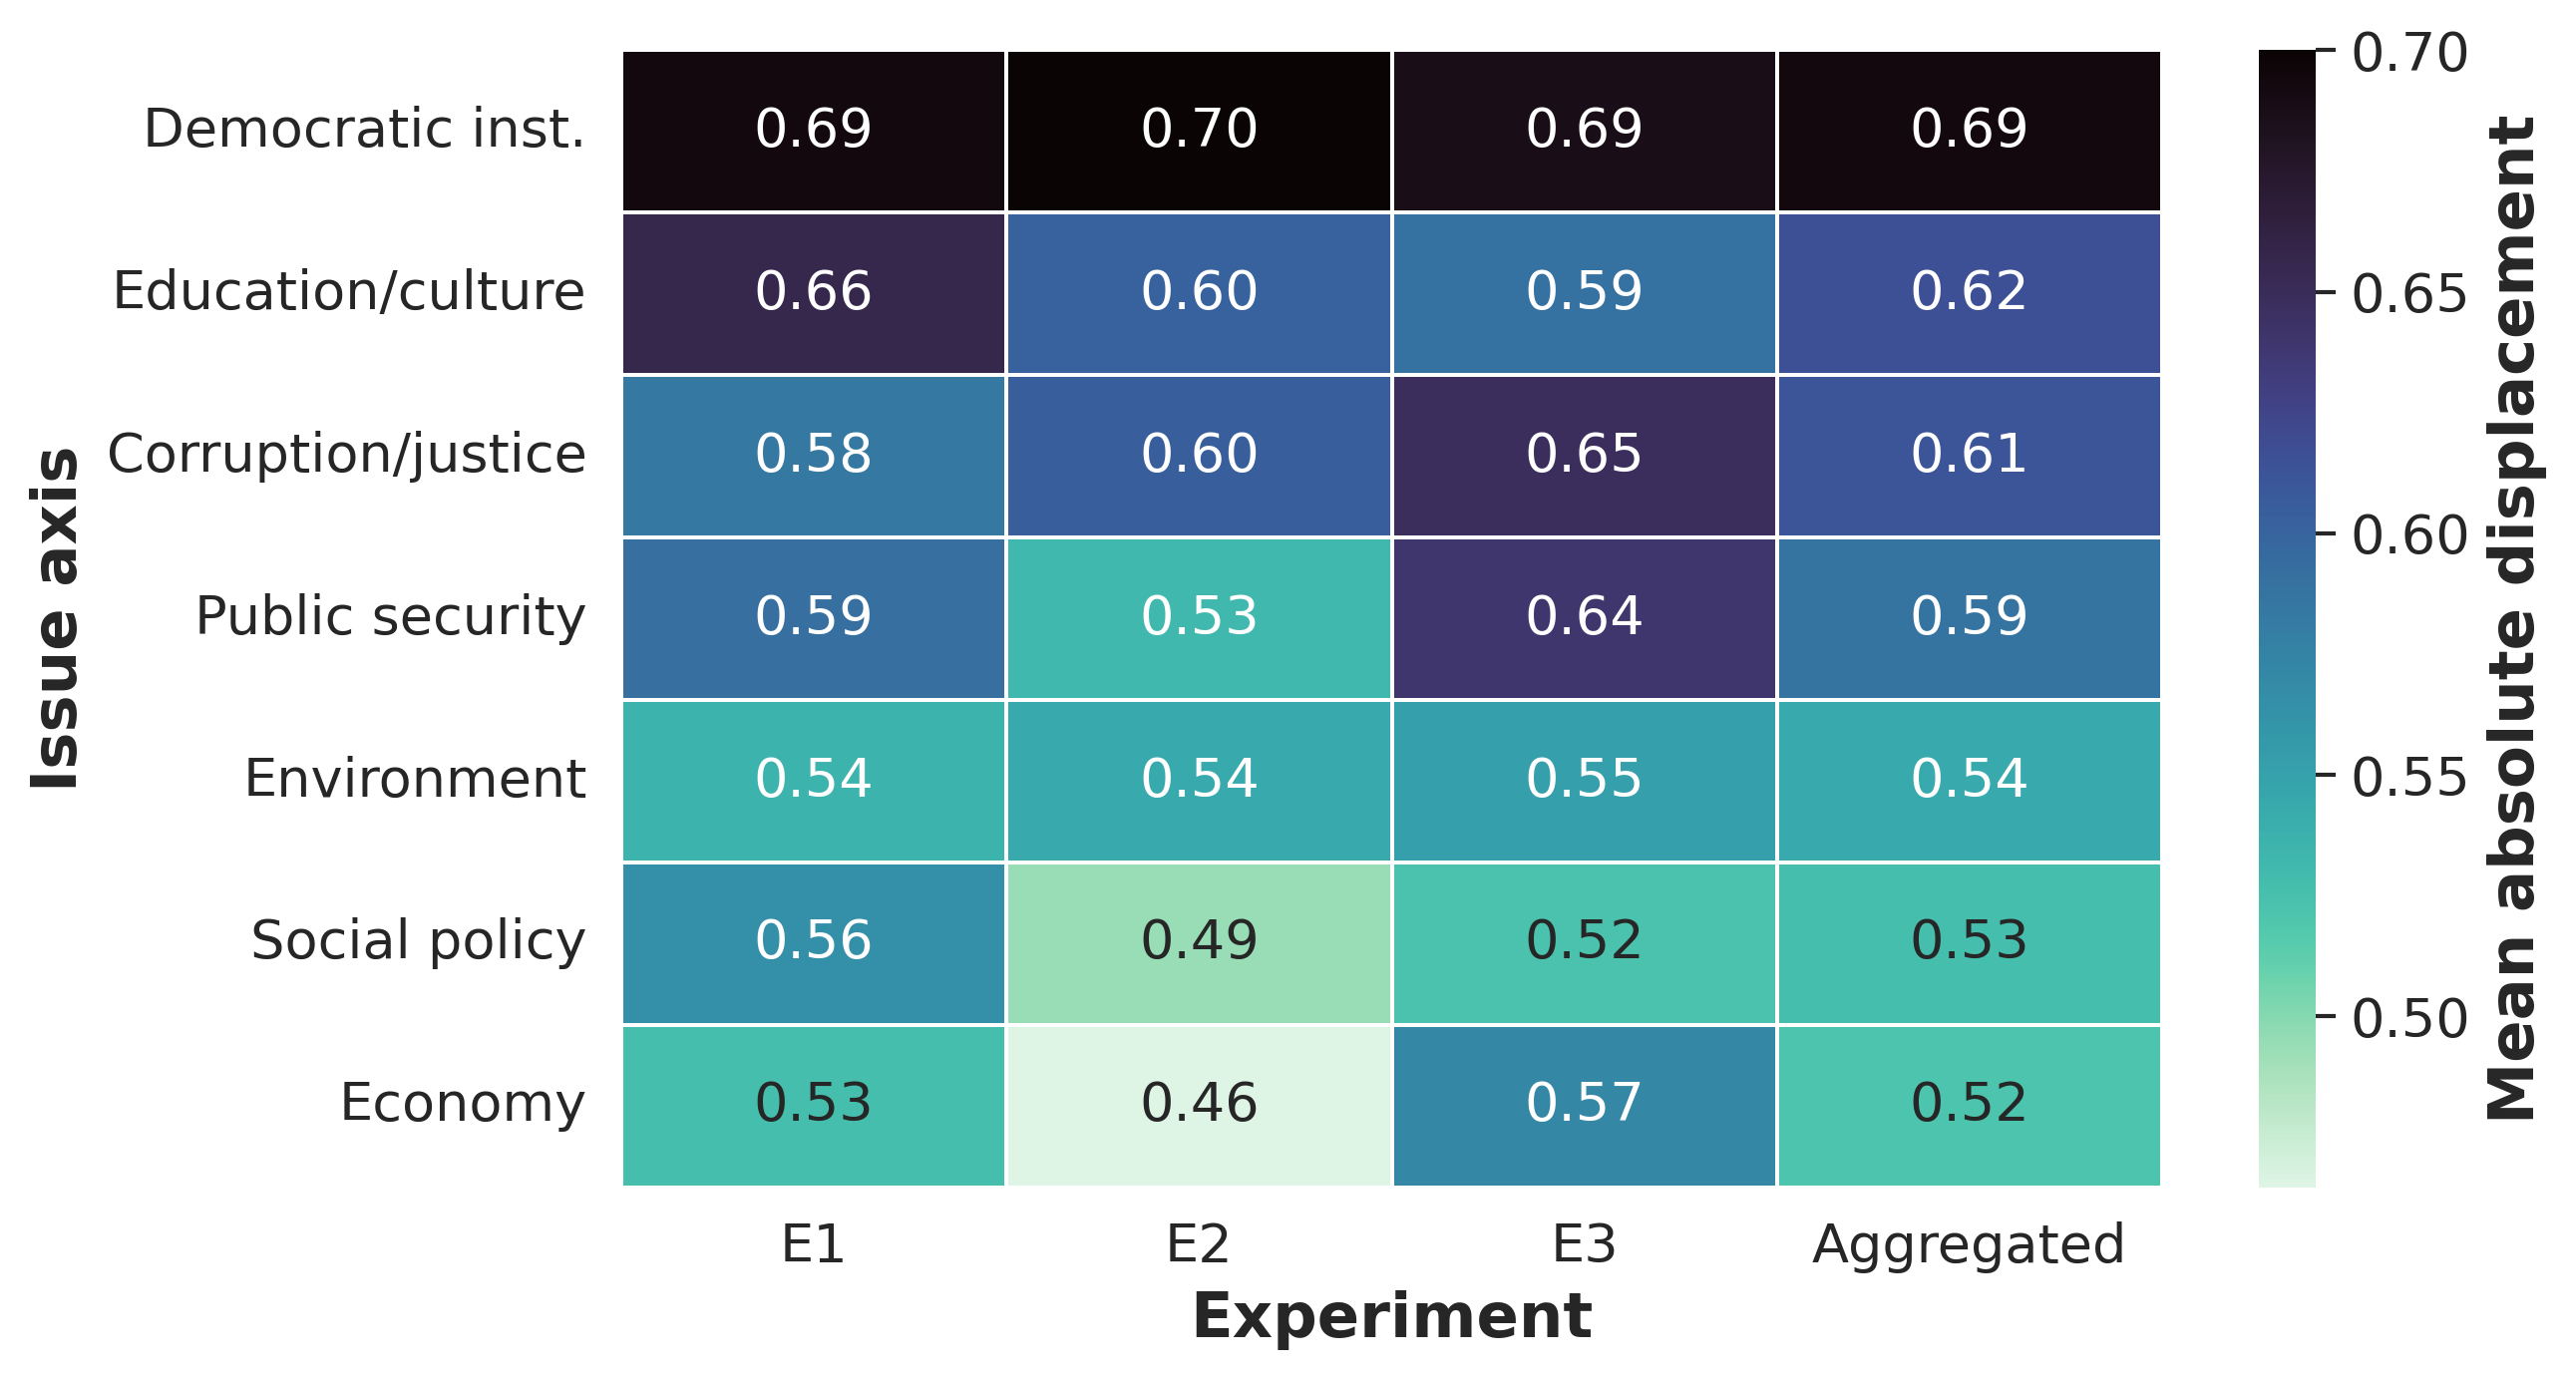

Saved figures/png/figure_6.png and figures/pdf/figure_6.pdf


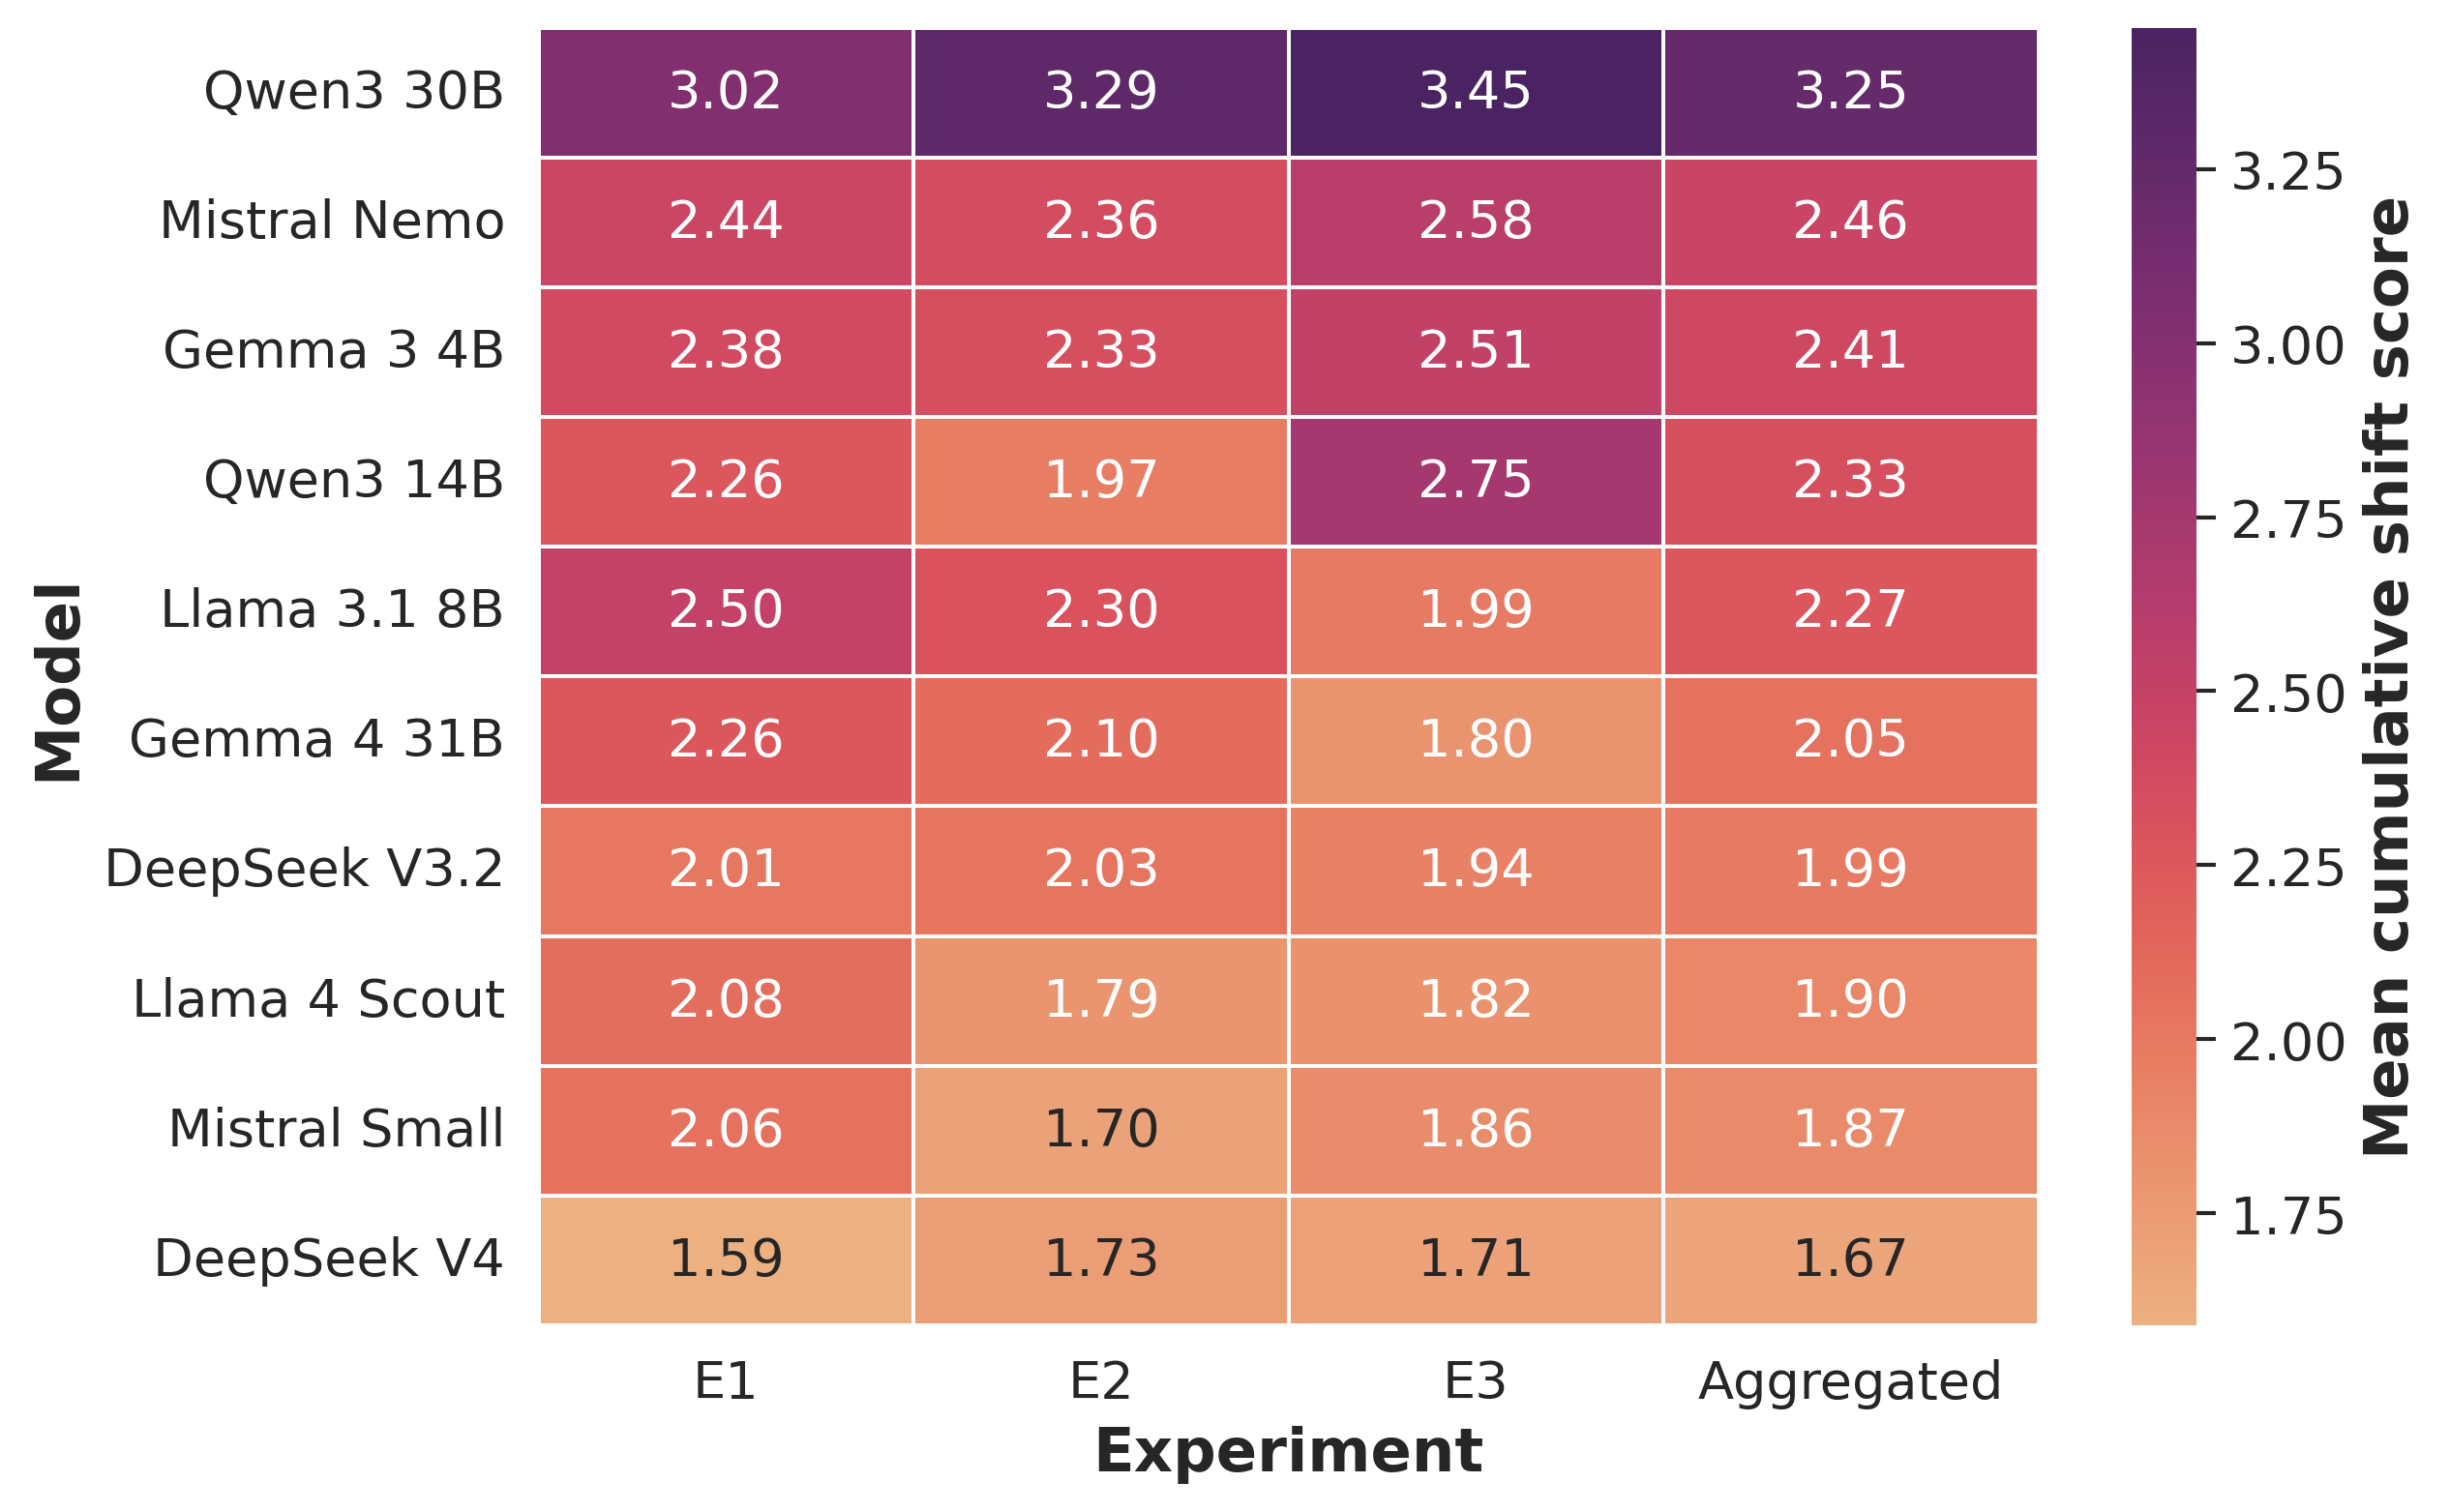

In [28]:
plot_figure_2(trajectories)
plot_figure_3(trajectories)
plot_figure_4(trajectories)
plot_figure_5(trajectories)
plot_figure_6(trajectories)

## Statistical Results for the Paper Text

The cells below generate the Kruskal-Wallis tests, epsilon squared effect sizes, Dunn-Holm pairwise checks, and parameter-count correlations reported in the Results section.


In [29]:
def model_stability_tests(traj):
    rows = []
    for exp, sub in traj.groupby('experiment'):
        h_stat, p_value, eps2, n, k = kruskal_by_group(sub, 'std', 'modelo')
        rows.append({
            'experiment': exp,
            'H': h_stat,
            'p': p_value,
            'epsilon_squared': eps2,
            'n_trajectories': n,
            'n_models': k,
            'significant_at_0_05': bool(p_value < .05) if not pd.isna(p_value) else False,
        })
    return pd.DataFrame(rows).sort_values('experiment')


def model_stability_dunn_holm(traj):
    try:
        import scikit_posthocs as sp
    except ImportError:
        return pd.DataFrame({'note': ['scikit_posthocs is not installed; Dunn-Holm table was not generated.']})

    rows = []
    for exp, sub in traj.groupby('experiment'):
        med = sub.groupby('modelo')['std'].median().sort_values()
        best_model = med.index[0]
        pmat = sp.posthoc_dunn(sub, val_col='std', group_col='modelo', p_adjust='holm')
        for model in med.index[1:]:
            rows.append({
                'experiment': exp,
                'most_stable_model': short_model_name(best_model),
                'comparison_model': short_model_name(model),
                'most_stable_median_sd': med.loc[best_model],
                'comparison_median_sd': med.loc[model],
                'holm_adjusted_p': float(pmat.loc[best_model, model]),
                'significant_at_0_05': bool(pmat.loc[best_model, model] < .05),
            })
    return pd.DataFrame(rows)


def scenario_variance_tests(traj):
    rows = []
    for (exp, condition), sub in traj.groupby(['experiment', 'condition']):
        h_stat, p_value, eps2, n, k = kruskal_by_group(sub, 'variance', 'modelo')
        rows.append({
            'experiment': exp,
            'scenario': 'no-context' if condition == 'Neutral' else condition,
            'H': h_stat,
            'p': p_value,
            'epsilon_squared': eps2,
            'n_trajectories': n,
            'n_models': k,
            'significant_at_0_05': bool(p_value < .05) if not pd.isna(p_value) else False,
        })
    return pd.DataFrame(rows).sort_values(['experiment', 'scenario'])


def scenario_pvalue_table(scenario_tests):
    order = ['Left', 'no-context', 'Right']
    return (
        scenario_tests.pivot(index='experiment', columns='scenario', values='p')
        .reindex(index=EXPERIMENT_ORDER, columns=order)
        .reset_index()
    )


def parameter_count_correlations(traj):
    model_protocol = (
        traj.groupby(['experiment', 'modelo'], as_index=False)
        .agg(mean_abs_first_to_final_displacement=('first_to_final_abs_delta', 'mean'))
    )
    metadata = pd.DataFrame([{'modelo': model, **meta} for model, meta in MODEL_METADATA.items()])
    data = model_protocol.merge(metadata, on='modelo', how='left')
    aggregated = (
        data.groupby(['modelo', 'family', 'params_b'], dropna=False, as_index=False)
        .agg(mean_abs_first_to_final_displacement=('mean_abs_first_to_final_displacement', 'mean'))
    )
    aggregated['experiment'] = 'Aggregated'
    corr_data = pd.concat([data, aggregated], ignore_index=True)

    rows = []
    for exp, sub in corr_data.dropna(subset=['params_b']).groupby('experiment'):
        if len(sub) >= 3 and sub['params_b'].nunique() >= 3:
            pearson_r, pearson_p = stats.pearsonr(sub['params_b'], sub['mean_abs_first_to_final_displacement'])
            spearman_rho, spearman_p = stats.spearmanr(sub['params_b'], sub['mean_abs_first_to_final_displacement'])
        else:
            pearson_r = pearson_p = spearman_rho = spearman_p = np.nan
        rows.append({
            'scope': exp,
            'n_models_with_known_params': len(sub),
            'pearson_r': pearson_r,
            'pearson_p': pearson_p,
            'spearman_rho': spearman_rho,
            'spearman_p': spearman_p,
        })
    return pd.DataFrame(rows).sort_values('scope')


def issue_axis_tests(traj):
    rows = []
    for exp, sub in traj.groupby('experiment'):
        h_stat, p_value, eps2, n, k = kruskal_by_group(sub, 'first_to_final_abs_delta', 'eixo')
        rows.append({
            'scope': exp,
            'H': h_stat,
            'p': p_value,
            'epsilon_squared': eps2,
            'n_trajectories': n,
            'n_issue_axes': k,
            'significant_at_0_05': bool(p_value < .05) if not pd.isna(p_value) else False,
        })
    h_stat, p_value, eps2, n, k = kruskal_by_group(traj, 'first_to_final_abs_delta', 'eixo')
    rows.append({
        'scope': 'Aggregated',
        'H': h_stat,
        'p': p_value,
        'epsilon_squared': eps2,
        'n_trajectories': n,
        'n_issue_axes': k,
        'significant_at_0_05': bool(p_value < .05) if not pd.isna(p_value) else False,
    })
    return pd.DataFrame(rows)


def cumulative_shift_tests(traj):
    rows = []
    for exp, sub in traj.groupby('experiment'):
        h_stat, p_value, eps2, n, k = kruskal_by_group(sub, 'cumulative_abs_shift_from_first', 'modelo')
        rows.append({
            'scope': exp,
            'H': h_stat,
            'p': p_value,
            'epsilon_squared': eps2,
            'n_trajectories': n,
            'n_models': k,
            'significant_at_0_05': bool(p_value < .05) if not pd.isna(p_value) else False,
        })
    h_stat, p_value, eps2, n, k = kruskal_by_group(traj, 'cumulative_abs_shift_from_first', 'modelo')
    rows.append({
        'scope': 'Aggregated',
        'H': h_stat,
        'p': p_value,
        'epsilon_squared': eps2,
        'n_trajectories': n,
        'n_models': k,
        'significant_at_0_05': bool(p_value < .05) if not pd.isna(p_value) else False,
    })
    return pd.DataFrame(rows)


In [30]:
model_tests = model_stability_tests(trajectories)
dunn_holm = model_stability_dunn_holm(trajectories)
scenario_tests = scenario_variance_tests(trajectories)
scenario_pvalues = scenario_pvalue_table(scenario_tests)
size_correlations = parameter_count_correlations(trajectories)
axis_tests = issue_axis_tests(trajectories)
cum_tests = cumulative_shift_tests(trajectories)

print('Model-level stability Kruskal-Wallis tests')
display(model_tests)

print('Dunn-Holm pairwise checks against the lowest-median-SD model')
display(dunn_holm)

print('Scenario-specific variance Kruskal-Wallis tests')
display(scenario_tests)

print('Scenario-specific p-value table')
display(scenario_pvalues)

print('Parameter-count correlations')
display(size_correlations)

print('Issue-axis Kruskal-Wallis tests')
display(axis_tests)

print('Cumulative-shift Kruskal-Wallis tests')
display(cum_tests)


Model-level stability Kruskal-Wallis tests


,experiment,H,p,epsilon_squared,n_trajectories,n_models,significant_at_0_05
0,E1,111.249737,8.182958e-20,0.030522,3360,10,True
1,E2,153.127432,1.982811e-28,0.043049,3358,10,True
2,E3,247.247693,3.801269e-48,0.071119,3360,10,True


Dunn-Holm pairwise checks against the lowest-median-SD model


,experiment,most_stable_model,comparison_model,most_stable_median_sd,comparison_median_sd,holm_adjusted_p,significant_at_0_05
0,E1,DeepSeek V3.2,DeepSeek V4,0.0,0.000000,1.000000e+00,False
1,E1,DeepSeek V3.2,Llama 4 Scout,0.0,0.000000,1.000000e+00,False
2,E1,DeepSeek V3.2,Llama 3.1 8B,0.0,0.000000,1.000000e+00,False
3,E1,DeepSeek V3.2,Mistral Nemo,0.0,0.000000,1.000000e+00,False
4,E1,DeepSeek V3.2,Qwen3 14B,0.0,0.400000,1.402236e-01,False
5,E1,DeepSeek V3.2,Gemma 3 4B,0.0,0.400000,1.000000e+00,False
6,E1,DeepSeek V3.2,Gemma 4 31B,0.0,0.400000,1.000000e+00,False
7,E1,DeepSeek V3.2,Mistral Small,0.0,0.400000,1.000000e+00,False
8,E1,DeepSeek V3.2,Qwen3 30B,0.0,0.489898,4.819760e-14,True
9,E2,DeepSeek V3.2,DeepSeek V4,0.0,0.000000,1.000000e+00,False


Scenario-specific variance Kruskal-Wallis tests


,experiment,scenario,H,p,epsilon_squared,n_trajectories,n_models,significant_at_0_05
0,E1,Left,42.836976,2.309310e-06,0.030484,1120,10,True
2,E1,Right,87.223899,5.861127e-15,0.070472,1120,10,True
1,E1,no-context,70.723734,1.098065e-11,0.055607,1120,10,True
3,E2,Left,38.196089,1.607441e-05,0.026303,1120,10,True
5,E2,Right,93.078211,3.919362e-16,0.075883,1118,10,True
4,E2,no-context,55.474585,9.888694e-09,0.041869,1120,10,True
6,E3,Left,92.616591,4.853614e-16,0.075330,1120,10,True
8,E3,Right,146.970735,3.738191e-27,0.124298,1120,10,True
7,E3,no-context,97.836262,4.306880e-17,0.080033,1120,10,True


... (4 outputs left out)

Issue-axis Kruskal-Wallis tests


,scope,H,p,epsilon_squared,n_trajectories,n_issue_axes,significant_at_0_05
0,E1,9.775588,0.134426,0.001126,3360,7,False
1,E2,20.212467,0.002538,0.004241,3358,7,True
2,E3,12.862696,0.045269,0.002047,3360,7,True
3,Aggregated,33.801987,0.000007,0.002761,10078,7,True


Cumulative-shift Kruskal-Wallis tests


,scope,H,p,epsilon_squared,n_trajectories,n_models,significant_at_0_05
0,E1,80.566422,1.247175e-13,0.021363,3360,10,True
1,E2,120.024013,1.321127e-21,0.033161,3358,10,True
2,E3,166.100018,4.002666e-31,0.046896,3360,10,True
3,Aggregated,332.479731,3.304131e-66,0.032129,10078,10,True
